# Project 2 · Milestone 1 — Dataset Preparation (Flickr30k)

**Goal:** build a clean, reproducible set of **2,000 image–caption pairs** for our text-to-image project.

What this notebook does, in order:

1. Streams Flickr30k from Hugging Face (no 4.4 GB full download)
2. Cleans captions: fixes spacing, length filter, quality checks, content filter
3. Checks images: minimum size, aspect ratio, near-duplicate removal
4. Resizes every image to **512×512** (Stable Diffusion 1.5's native size)
5. Splits into train / val / test (80 / 10 / 10)
6. Shows normalization, statistics and sample pairs for the dataset memo
7. Saves everything (`images/`, `metadata.csv`, `dataset_config.json`) and zips it

**Runtime:** Colab, CPU is enough for this notebook. Takes about 5–10 minutes.

## 1. Install libraries
`datasets` streams the data from Hugging Face. `imagehash` gives each image a "fingerprint" so we can catch duplicate photos.

In [ ]:
!pip install -q datasets imagehash

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 10.7 MB/s eta 0:00:00


## 2. Imports and settings
All the choices for the dataset live in this one cell, so anyone on the team can see them and rerun with the same values. `SEED` makes the random choices repeatable.

In [ ]:
import os, re, json, random, shutil
from collections import Counter

import numpy as np
import pandas as pd
from PIL import Image
import imagehash
import matplotlib.pyplot as plt
from datasets import load_dataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DATASET_NAME = "lmms-lab-encoder/flickr30k"   # Flickr30k, parquet version on Hugging Face
TARGET_PAIRS = 2000          # assignment asks for roughly 1k–5k
IMG_SIZE     = 512           # Stable Diffusion 1.5 works at 512x512
MIN_SIDE     = 256           # skip images that are too small
MAX_ASPECT   = 2.0           # skip very wide/tall images (center crop would cut too much)
MIN_WORDS, MAX_WORDS = 6, 30 # caption length filter (CLIP reads at most 77 tokens)
TARGET_WORDS = 15            # among the 5 captions, prefer one close to this length
NEAR_DUP_DIST = 4            # image fingerprints this close count as duplicates

OUT_DIR = "data/flickr30k_subset"
IMG_DIR = os.path.join(OUT_DIR, "images")
os.makedirs(IMG_DIR, exist_ok=True)
print("Saving to:", os.path.abspath(OUT_DIR))

Saving to: /content/data/flickr30k_subset


## 3. Load the dataset (streaming) and look at one example
Each row has one image and **5 human-written captions**. Streaming means we only download the rows we actually use.

README.md:   0%|          | 0.00/2.23k [00:00<?, ?B/s]

Columns: ['image', 'caption', 'sentids', 'img_id', 'filename']
Image size: (333, 500)
  caption 1: Two young guys with shaggy hair look at their hands while hanging out in the yard .
  caption 2: Two young  White males are outside near many bushes .
  caption 3: Two men in green shirts are standing in a yard .
  caption 4: A man in a blue shirt standing in a garden .
  caption 5: Two friends enjoy time spent together .


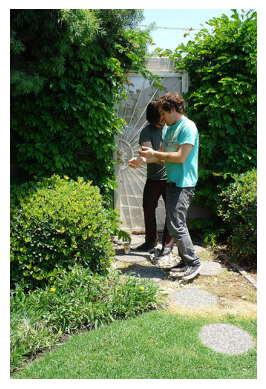

In [ ]:
raw = load_dataset(DATASET_NAME, split="test", streaming=True)

example = next(iter(raw))
print("Columns:", list(example.keys()))
print("Image size:", example["image"].size)
for i, c in enumerate(example["caption"]):
    print(f"  caption {i+1}: {c}")
plt.imshow(example["image"]); plt.axis("off"); plt.show()

# Shuffle so our subset is a random sample, not just the first rows of the file
ds = raw.shuffle(seed=SEED, buffer_size=2000)

## 4. Caption cleaning rules
Flickr30k captions have tokenizer spacing like `"a dog ."` and `"man 's hat"`. We fix that, then check each caption:

| Check | Why |
|---|---|
| 6–30 words | too short = vague, too long = CLIP cuts it off at 77 tokens |
| no `?` | a question mark means the annotator was unsure (e.g. "modern art ?") |
| mostly letters | removes junk or broken captions |
| content filter | removes captions with nudity, violence or weapon words |

Each image has 5 captions; we keep the valid one closest to 15 words (descriptive but not rambling) and store the other valid ones as alternates.

In [ ]:
BLOCKLIST = {"nude", "naked", "topless", "sexy", "blood", "bloody", "gun", "guns",
             "rifle", "pistol", "weapon", "weapons", "corpse", "kill", "killing"}

def clean_caption(text):
    t = text.strip()
    t = re.sub(r"\s+([.,!;:'])", r"\1", t)   # "dog ." -> "dog."   "man 's" -> "man's"
    t = re.sub(r"\s+", " ", t)                # collapse repeated spaces
    t = t.strip(" .")                         # drop the trailing period
    if t:
        t = t[0].upper() + t[1:]
    return t

def word_count(t):
    return len(t.split())

def caption_check(t):
    """Returns (is_ok, reason)."""
    n = word_count(t)
    if n < MIN_WORDS: return False, "too_short"
    if n > MAX_WORDS: return False, "too_long"
    if "?" in t:      return False, "uncertain"
    if sum(c.isalpha() for c in t) / max(len(t), 1) < 0.7:
        return False, "non_alpha"
    if set(re.findall(r"[a-z]+", t.lower())) & BLOCKLIST:
        return False, "content_filter"
    return True, "ok"

caption_reasons = Counter()   # why individual captions were rejected (for the memo)

def pick_caption(captions):
    """Clean all 5 captions, keep the valid ones, return (best, all_valid)."""
    valid = []
    for c in captions:
        c = clean_caption(c)
        ok, reason = caption_check(c)
        caption_reasons[reason] += 1
        if ok and c not in valid:
            valid.append(c)
    if not valid:
        return None, []
    best = min(valid, key=lambda c: abs(word_count(c) - TARGET_WORDS))
    return best, valid

# Quick test on the example above
best, valid = pick_caption(example["caption"])
print("Chosen caption:", best)
print("Valid alternates:", len(valid))

Chosen caption: Two young guys with shaggy hair look at their hands while hanging out in the yard
Valid alternates: 5


## 5. Image checks and resizing
- **Size / aspect checks:** skip images smaller than 256 px or more than 2:1 wide/tall.
- **Center crop + resize:** cut the largest centered square, then resize to 512×512. Squashing without cropping would distort people and objects.
- **Near-duplicate check:** a *perceptual hash* is a short fingerprint of what an image looks like. Two photos with nearly the same fingerprint are treated as duplicates.

Note: Flickr30k images are at most 500 px on a side, so going to 512 is a slight upscale. That's fine for Stable Diffusion's input size.

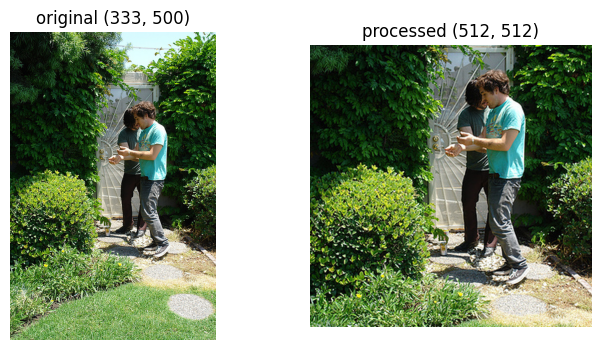

In [ ]:
def image_check(img):
    w, h = img.size
    if min(w, h) < MIN_SIDE:
        return False, "too_small"
    if max(w, h) / min(w, h) > MAX_ASPECT:
        return False, "bad_aspect"
    return True, "ok"

def center_crop_resize(img, size=IMG_SIZE):
    img = img.convert("RGB")
    w, h = img.size
    s = min(w, h)
    left, top = (w - s) // 2, (h - s) // 2
    img = img.crop((left, top, left + s, top + s))
    return img.resize((size, size), Image.LANCZOS)

# Show before/after on the example
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(example["image"]); ax[0].set_title(f"original {example['image'].size}")
ax[1].imshow(center_crop_resize(example["image"])); ax[1].set_title(f"processed ({IMG_SIZE}, {IMG_SIZE})")
for a in ax: a.axis("off")
plt.show()

## 6. Build the subset
This loop goes through shuffled rows and keeps a pair only if it passes **every** check. It stops at 2,000 pairs. The `funnel` counter records how many rows each check removed; that table goes in the dataset memo.

In [ ]:
records, seen_captions, seen_hashes = [], set(), []
funnel = Counter()

for ex in ds:
    funnel["rows_seen"] += 1
    img = ex["image"]

    ok, reason = image_check(img)
    if not ok:
        funnel[f"dropped: image {reason}"] += 1
        continue

    best, valid = pick_caption(ex["caption"])
    if best is None:
        funnel["dropped: no valid caption"] += 1
        continue

    if best.lower() in seen_captions:
        funnel["dropped: duplicate caption"] += 1
        continue

    h = imagehash.phash(img.convert("RGB"))
    if any(h - prev <= NEAR_DUP_DIST for prev in seen_hashes):
        funnel["dropped: duplicate image"] += 1
        continue

    fname = os.path.splitext(ex["filename"])[0] + ".jpg"
    center_crop_resize(img).save(os.path.join(IMG_DIR, fname), quality=95)

    seen_captions.add(best.lower())
    seen_hashes.append(h)
    records.append({
        "image_id": ex["img_id"],
        "filename": fname,
        "caption": best,
        "n_words": word_count(best),
        "alt_captions": json.dumps(valid),
        "orig_width": img.size[0],
        "orig_height": img.size[1],
    })
    funnel["kept"] += 1

    if len(records) % 250 == 0:
        print(f"kept {len(records)} / {TARGET_PAIRS}  (rows seen: {funnel['rows_seen']})")
    if len(records) >= TARGET_PAIRS:
        break

df = pd.DataFrame(records)
print("\nDone. Pairs kept:", len(df))

kept 250 / 2000  (rows seen: 256)
kept 500 / 2000  (rows seen: 507)
kept 750 / 2000  (rows seen: 763)
kept 1000 / 2000  (rows seen: 1022)
kept 1250 / 2000  (rows seen: 1277)
kept 1500 / 2000  (rows seen: 1528)
kept 1750 / 2000  (rows seen: 1780)
kept 2000 / 2000  (rows seen: 2031)

Done. Pairs kept: 2000


## 7. Cleaning summary (for the dataset memo)

In [ ]:
funnel_df = pd.DataFrame(sorted(funnel.items(), key=lambda kv: -kv[1]), columns=["step", "count"])
display(funnel_df)

reason_df = pd.DataFrame(caption_reasons.most_common(), columns=["caption check", "count"])
reason_df["percent"] = (100 * reason_df["count"] / reason_df["count"].sum()).round(1)
display(reason_df)

,step,count
0,rows_seen,2031
1,kept,2000
2,dropped: image too_small,30
3,dropped: no valid caption,1


,caption check,count,percent
0,ok,9526,95.2
1,too_short,378,3.8
2,too_long,65,0.6
3,content_filter,34,0.3
4,uncertain,6,0.1
5,non_alpha,1,0.0


## 8. Train / validation / test split
80 / 10 / 10, random with our fixed seed. Later milestones use **test** for evaluation (FID, Inception Score) and never train or tune on it.

In [ ]:
df = df.sample(frac=1, random_state=SEED).reset_index(drop=True)
n = len(df)
n_train, n_val = int(0.8 * n), int(0.1 * n)
df["split"] = ["train"] * n_train + ["val"] * n_val + ["test"] * (n - n_train - n_val)
print(df["split"].value_counts())

split
train    1600
val       200
test      200
Name: count, dtype: int64


## 9. Normalization
Stable Diffusion's image encoder (VAE) expects pixel values in **[-1, 1]**, channels first (3 × 512 × 512). This function does that conversion; we check it on one image.

We also compute the dataset's average color per channel, which is useful in the memo. (CLIP uses its own normalization; its processor handles that in the CLIP notebook.)

In [ ]:
def to_model_array(img):
    """PIL image -> float array (3, H, W) scaled to [-1, 1]."""
    arr = np.asarray(img.convert("RGB"), dtype=np.float32) / 255.0   # [0, 1]
    arr = arr * 2.0 - 1.0                                             # [-1, 1]
    return arr.transpose(2, 0, 1)                                      # HWC -> CHW

x = to_model_array(Image.open(os.path.join(IMG_DIR, df.loc[0, "filename"])))
print("shape:", x.shape, "| min:", round(float(x.min()), 3), "| max:", round(float(x.max()), 3))

# Per-channel mean / std over a random sample of 200 images (in [0, 1] scale)
sample = df.sample(min(200, len(df)), random_state=SEED)
pix = np.stack([np.asarray(Image.open(os.path.join(IMG_DIR, f)), dtype=np.float32) / 255.0
                for f in sample["filename"]])
print("channel mean (R,G,B):", pix.mean(axis=(0, 1, 2)).round(3))
print("channel std  (R,G,B):", pix.std(axis=(0, 1, 2)).round(3))

shape: (3, 512, 512) | min: -1.0 | max: 1.0
channel mean (R,G,B): [0.32 0.32 0.32]
channel std  (R,G,B): [0.288 0.266 0.261]


## 10. Dataset statistics and domain coverage
Caption lengths and which kinds of scenes the subset covers. Flickr30k is heavily focused on **people doing everyday activities**; the keyword table shows that.

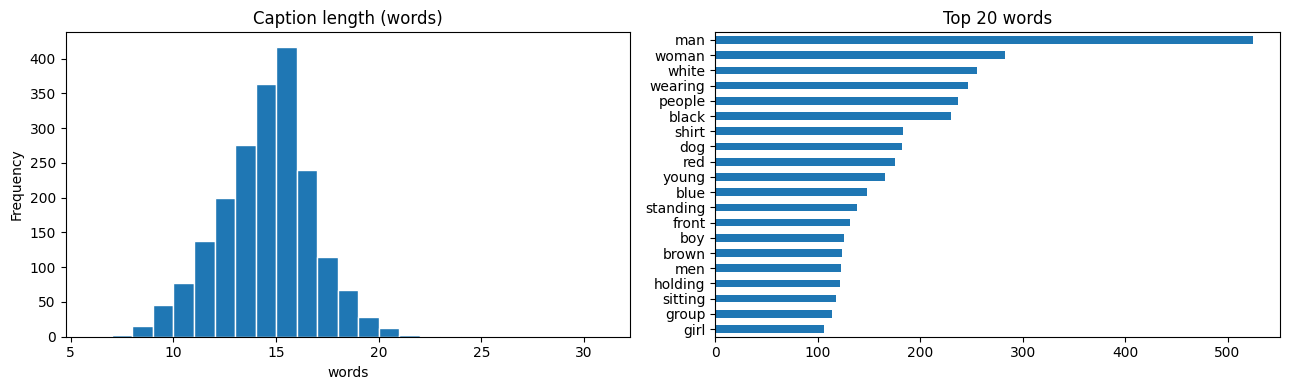

,domain,% of captions
0,people,70.2
1,animals,12.2
2,sports,15.5
3,water / beach,7.8
4,city / street,10.4
5,nature,13.4
6,indoor,5.8


Average caption length: 14.0 words


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
df["n_words"].plot.hist(bins=range(MIN_WORDS, MAX_WORDS + 2), ax=ax[0], edgecolor="white")
ax[0].set_title("Caption length (words)"); ax[0].set_xlabel("words")

STOP = set("a an the of in on at with and is are to his her their its while for by from near "
           "two three one some other another into up down over as it that this".split())
words = Counter(w for c in df["caption"] for w in re.findall(r"[a-z]+", c.lower()) if w not in STOP)
top = pd.Series(dict(words.most_common(20)))
top.sort_values().plot.barh(ax=ax[1]); ax[1].set_title("Top 20 words")
plt.tight_layout(); plt.show()

DOMAINS = {
    "people":        ["man", "woman", "men", "women", "person", "people", "boy", "girl", "child", "children", "kid", "kids", "guy", "guys", "lady"],
    "animals":       ["dog", "dogs", "cat", "horse", "bird", "animal", "cow", "sheep"],
    "sports":        ["playing", "ball", "soccer", "football", "basketball", "bike", "bicycle", "skateboard", "running", "player"],
    "water / beach": ["water", "beach", "ocean", "lake", "river", "pool", "swimming", "surf"],
    "city / street": ["street", "city", "building", "sidewalk", "road", "crowd"],
    "nature":        ["grass", "field", "tree", "trees", "mountain", "snow", "forest", "park"],
    "indoor":        ["room", "kitchen", "table", "restaurant", "store", "stage"],
}
cov = {d: df["caption"].str.lower().str.contains(r"\b(?:" + "|".join(kw) + r")\b").mean() * 100
       for d, kw in DOMAINS.items()}
coverage_df = pd.DataFrame({"domain": cov.keys(), "% of captions": np.round(list(cov.values()), 1)})
display(coverage_df)
print("Average caption length:", round(df["n_words"].mean(), 1), "words")

## 11. Sample image–caption pairs

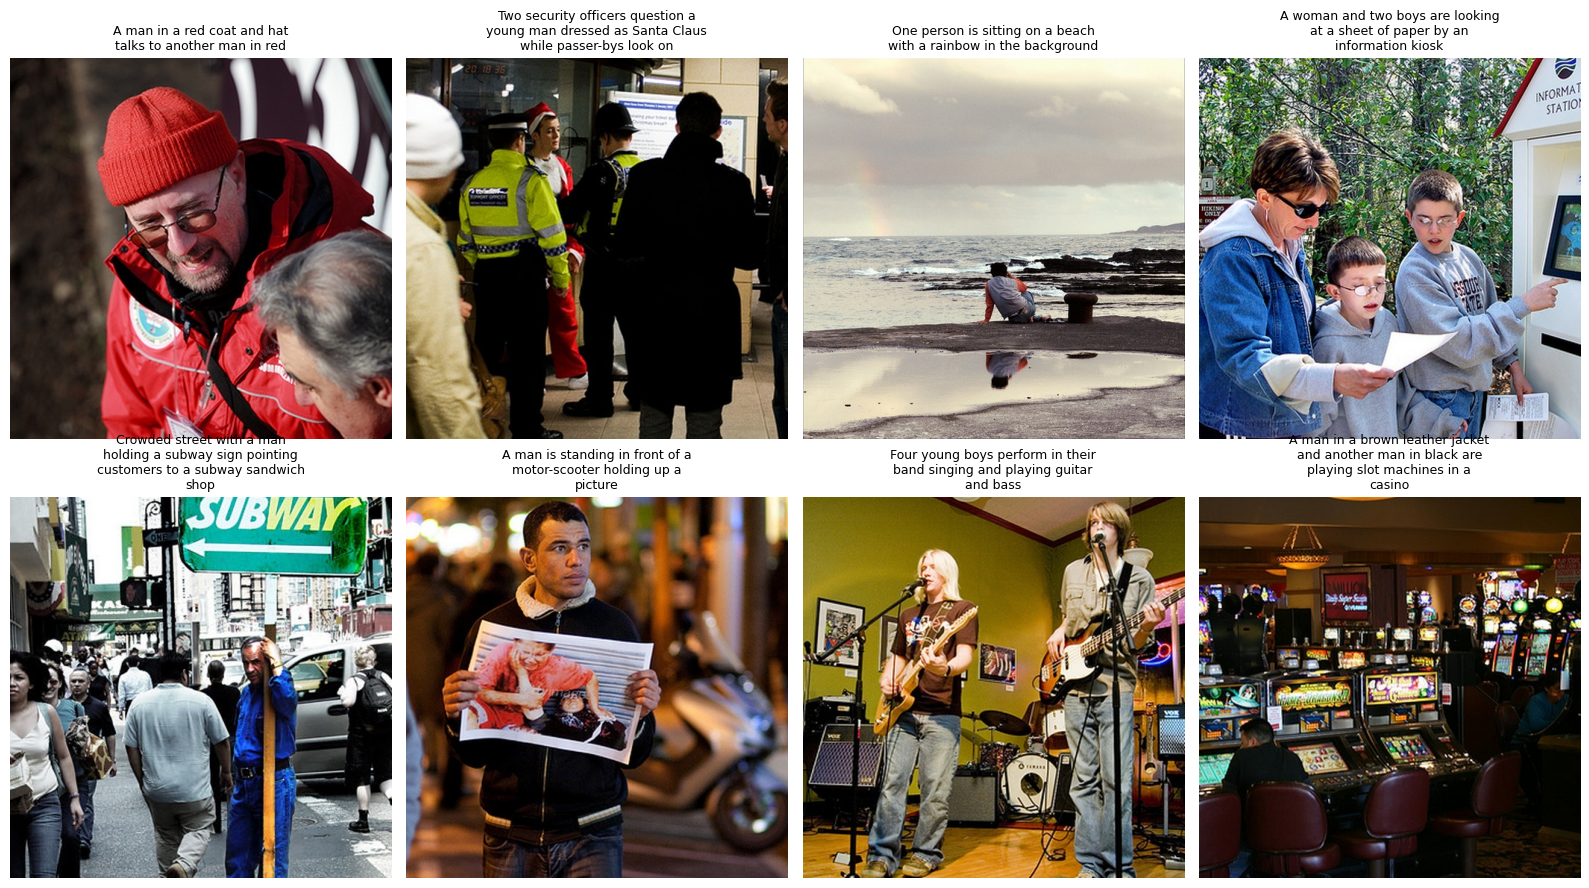

In [ ]:
import textwrap
show = df.sample(8, random_state=1)
fig, axes = plt.subplots(2, 4, figsize=(16, 9))
for ax, (_, row) in zip(axes.flat, show.iterrows()):
    ax.imshow(Image.open(os.path.join(IMG_DIR, row["filename"])))
    ax.set_title("\n".join(textwrap.wrap(row["caption"], 32)), fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "sample_pairs.png"), dpi=120, bbox_inches="tight")
plt.show()

## 12. Final verification
Automatic checks that the dataset is correct. If anything is wrong, this cell stops with an error.

In [ ]:
assert len(df) == TARGET_PAIRS, f"expected {TARGET_PAIRS} pairs, got {len(df)}"
assert df["caption"].str.lower().is_unique, "duplicate captions found"
assert df["filename"].is_unique, "duplicate filenames found"
assert df["n_words"].between(MIN_WORDS, MAX_WORDS).all(), "caption length out of range"
for f in df["filename"]:
    with Image.open(os.path.join(IMG_DIR, f)) as im:
        assert im.size == (IMG_SIZE, IMG_SIZE) and im.mode == "RGB", f"bad image: {f}"
print(f"All checks passed: {len(df)} pairs, all images {IMG_SIZE}x{IMG_SIZE} RGB, no duplicates.")

All checks passed: 2000 pairs, all images 512x512 RGB, no duplicates.


## 13. Save metadata and config
- `metadata.csv`: one row per pair (filename, caption, split, alternates, original size). The CLIP and Stable Diffusion notebooks load this file.
- `dataset_config.json`: every setting and the cleaning counts, so the subset can be rebuilt exactly.

In [ ]:
df.to_csv(os.path.join(OUT_DIR, "metadata.csv"), index=False)

config = {
    "dataset": DATASET_NAME, "seed": SEED, "target_pairs": TARGET_PAIRS,
    "image_size": IMG_SIZE, "min_side": MIN_SIDE, "max_aspect": MAX_ASPECT,
    "caption_words": [MIN_WORDS, MAX_WORDS], "target_words": TARGET_WORDS,
    "near_duplicate_hash_distance": NEAR_DUP_DIST, "blocklist": sorted(BLOCKLIST),
    "funnel": dict(funnel), "caption_check_counts": dict(caption_reasons),
    "split_counts": df["split"].value_counts().to_dict(),
}
with open(os.path.join(OUT_DIR, "dataset_config.json"), "w") as f:
    json.dump(config, f, indent=2)

print(os.listdir(OUT_DIR))
display(df.head())

['metadata.csv', 'dataset_config.json', 'sample_pairs.png', 'images']


,image_id,filename,caption,n_words,alt_captions,orig_width,orig_height,split
0,130,1042359076.jpg,Two little girls and an old man have a convers...,10,"[""A older man holds an object and is looking a...",500,333,train
1,12093,3207358897.jpg,An Asian girl performs a routine with two red ...,13,"[""An Asian girl performs a routine with two re...",500,375,train
2,10760,3049617203.jpg,Man wearing a red black and white jacket ridin...,18,"[""A man with a plaid shirt riding a bike going...",500,309,train
3,10886,3067500667.jpg,A man is standing in front of some red sticks ...,15,"[""A man is standing in front of some red stick...",500,333,train
4,13501,3362086744.jpg,A baseball player is putting all his might in ...,13,"[""A baseball player is putting all his might i...",500,400,train


## 14. Zip and download (or save to Google Drive)
The images are too large for GitHub, so the repo keeps this notebook plus `metadata.csv` and `dataset_config.json`; anyone can rebuild the images by rerunning the notebook.

In [ ]:
shutil.make_archive("flickr30k_subset", "zip", OUT_DIR)
print("Created flickr30k_subset.zip")

# Option A: download to your computer
# from google.colab import files; files.download("flickr30k_subset.zip")

# Option B: save to Google Drive so the CLIP and Stable Diffusion notebooks can reuse it
# from google.colab import drive; drive.mount("/content/drive")
# shutil.copy("flickr30k_subset.zip", "/content/drive/MyDrive/flickr30k_subset.zip")

Created flickr30k_subset.zip
